# Convergence checks for the tent map.
We computes $\lambda_2(d)$ for the tent map for different depths ($d$). From this, we plot the relative error in $\lambda_2(d)$ against the "limiting value" $\lambda_2(1,000)$

In [ ]:
# imports
import time

import matplotlib.pyplot as plt
import numpy as np

from chebyshev_hofbauer_resonances.general_tent_map.approx_transfer_op import (
    approx_super_adjacency,
    create_adjacency_matricies,
)

plt.rcParams.update({
    'font.family': 'serif',        # Matches typical LaTeX document fonts
    'font.size': 12,               # Base font size
    'axes.labelsize': 14,          # Larger axis labels
    'xtick.labelsize': 12,         # Tick sizes
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'axes.grid': True,             # Turn on grid
    'grid.alpha': 0.4,             # Make grid faint so it doesn't distract
    'grid.linestyle': '--',        # Dashed grid lines
    'figure.dpi': 300,             # 300 DPI is standard for publication
    # 'text.usetex': True          # Uncomment if you have a full LaTeX engine installed
})

In [3]:
# function definition
alpha = 1.6
function_domains = [(0, 0.5), (0.5, 1)]
functions = [lambda x: alpha * x, lambda x: alpha * (1 - x)]
inverses = [lambda y: y / alpha, lambda y: 1 - (y / alpha)]
derivatives = [lambda _: alpha, lambda _: -alpha]

In [ ]:
domains, adj_matrices = create_adjacency_matricies(
    function_domains, functions, depth=5
)

In [ ]:
# functions
def super_adj_spec(NK, depth, spec_size = 3):
    N = K = NK

    super_adjacency = approx_super_adjacency(
        function_domains,
        functions,
        inverses,
        derivatives,
        N=N,
        K=K,
        depth=depth,
    )

    evals_super_adj = np.linalg.eigvals(super_adjacency)
    evals_super_adj = evals_super_adj[np.argsort(-np.abs(evals_super_adj))]

    eval_mags = np.abs(evals_super_adj)

    spec = eval_mags[:spec_size]
    return spec, evals_super_adj

In [ ]:
spec_mags = []
specs = []
times = []

depths = np.arange(2, 1_000)

for d in depths:
    tic = time.time()
    res = super_adj_spec(1, d, 2)
    spec_mags.append(res[0])
    specs.append(res[1])
    toc = time.time()
    times.append(toc - tic)

spec_mags = np.array(spec_mags)

l2 = np.array([spec[1] for spec in specs])
error = np.abs(np.abs(l2) - np.abs(l2[-1])) / np.abs(l2[-1])

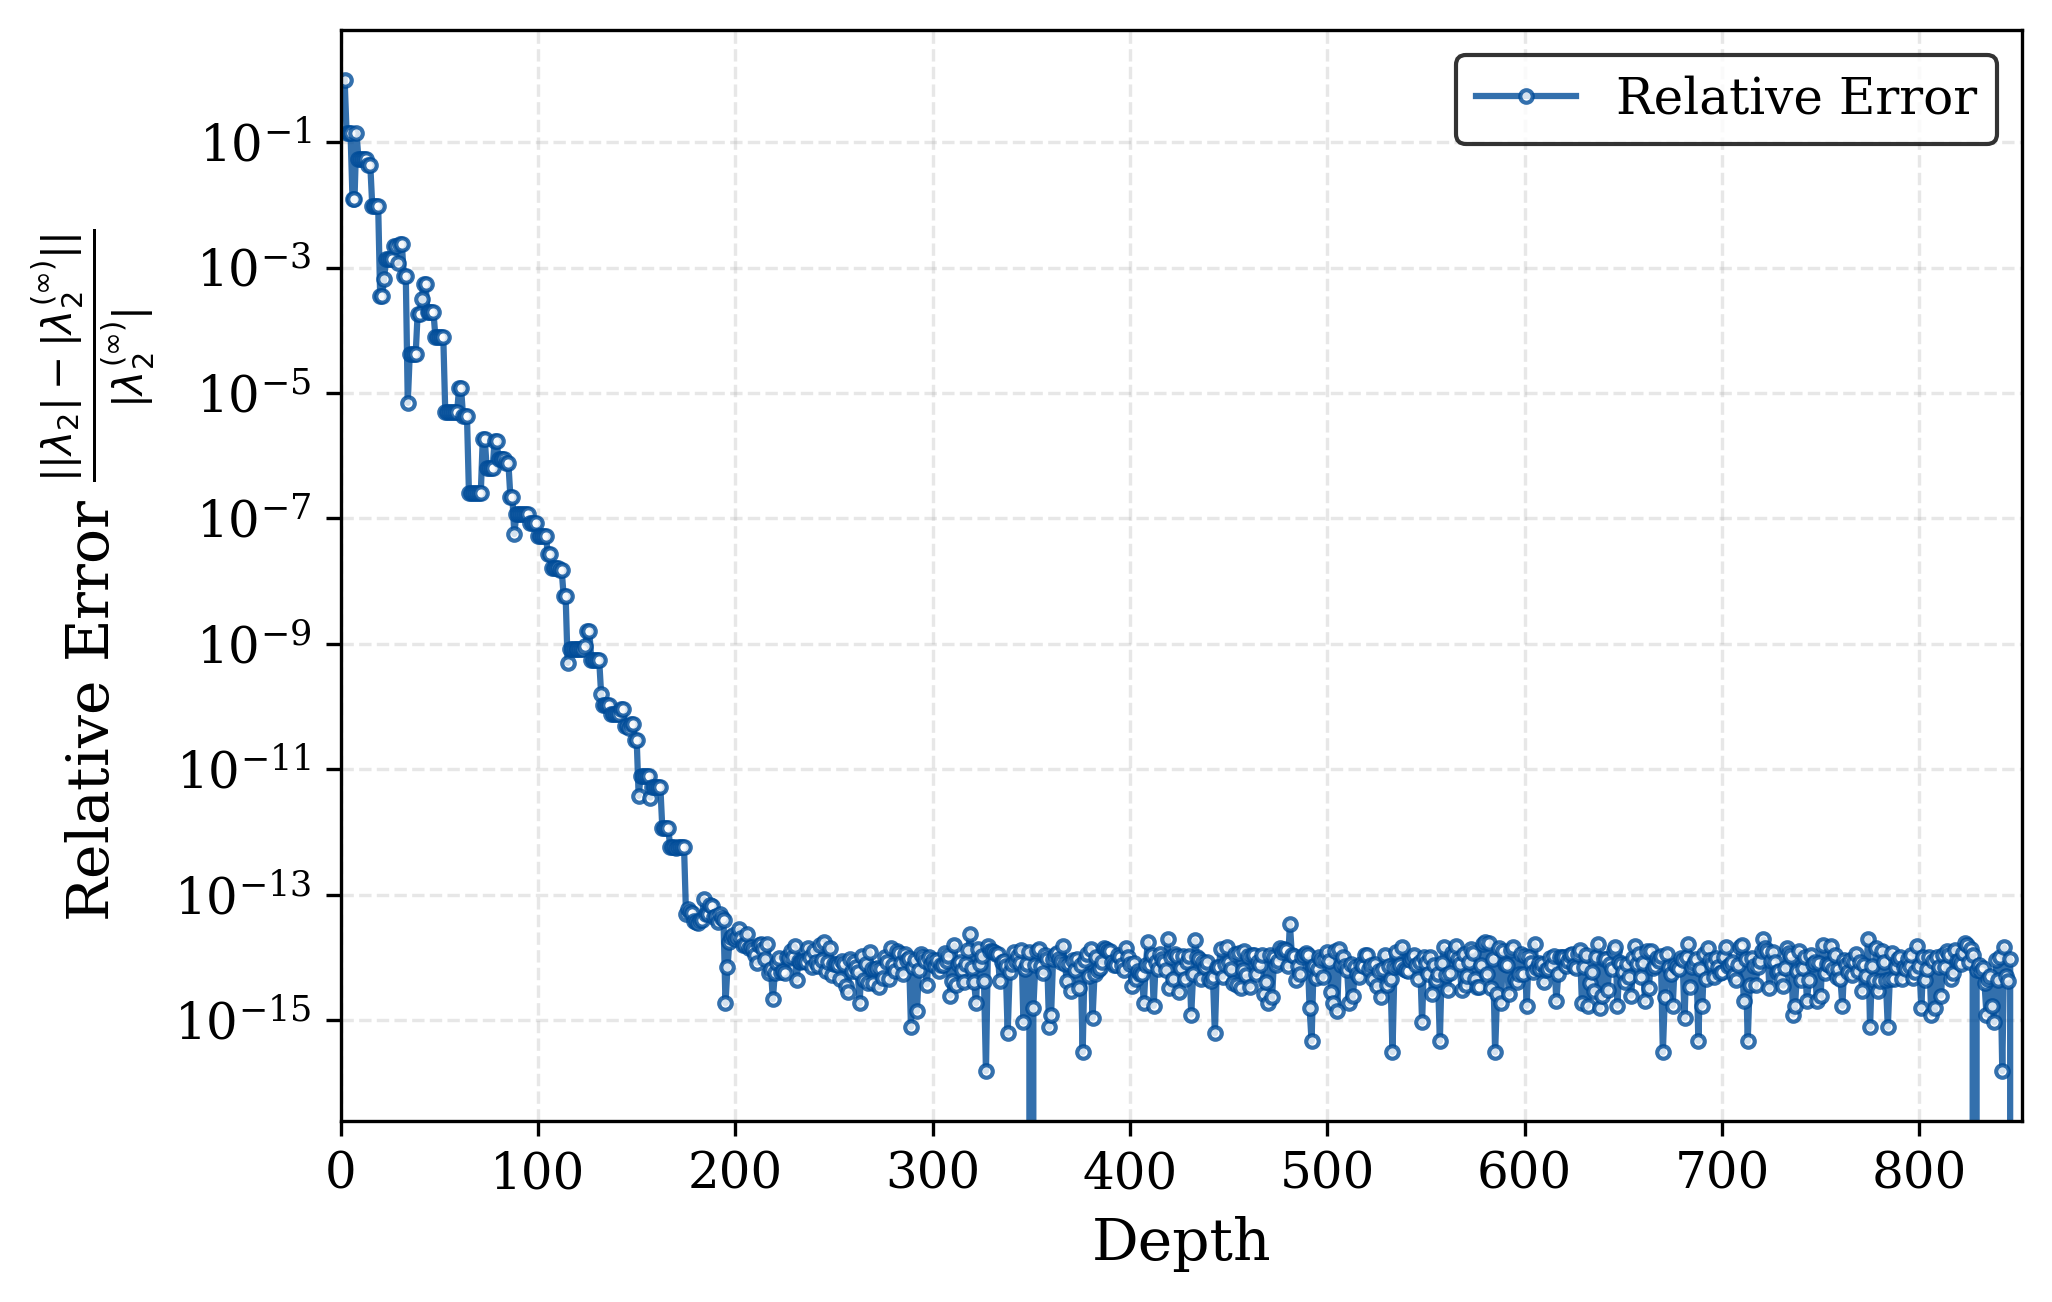

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(depths, error, color='#004c99', linestyle='-', linewidth=1.5,
        marker='o', markersize=3, markerfacecolor='white', markeredgewidth=1,
        alpha=0.8, label=r'Relative Error')

ax.set_yscale('log')
ax.set_xlabel('Depth')

ax.set_ylabel(r'Relative Error $\frac{ | |\lambda_2| - |\lambda_2^{(\infty)}| | }{ |\lambda_2^{(\infty)}| }$')

ax.set_xlim(0, max(depths) + 5) # Give a little breathing room on the right
ax.grid(True, which="both", ls="--", alpha=0.3) # Render minor tick grids for log scale
ax.legend(loc='upper right', frameon=True, edgecolor='black')

plt.tight_layout() # Ensures labels don't get cut off
plt.savefig('eigenvalue_convergence.pdf', format='pdf', bbox_inches='tight') # PDFs are lossless vectors, best for LaTeX
plt.show()